# Training with annotator agreement

84% of the val errors are on sentences where the annotators did not all agree. Here the model is told how sure the annotators were, in two ways:

| arm | what changes |
|---|---|
| `agreement_weight` | loss weight = agreement level (100% -> 1, 75% -> 0.75, 66% -> 0.66, 50% -> 0.5) |
| `soft_label` | target = agreement share on the gold label, the rest split evenly over the other two (66% positive -> [0.17, 0.17, 0.66]) |

Same recipe and seeds as notebook 06 (frozen FinBERT CNN, trained from scratch). The reference is the `no_weight` runs from notebook 06, scored again here with the fixed all-agree flag. Agreement levels come from `results/hard_samples/agreement_*.csv`. Val only.

## Imports

In [1]:
import os
os.environ["HF_HOME"] = os.path.abspath("../.cache/huggingface")
os.environ["HF_HUB_CACHE"] = os.path.abspath("../.cache/huggingface/hub")
import sys

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from tensorflow import keras
from matplotlib import pyplot as plt

sys.path.append("..")
from utils.finbert_cnn import SEEDS, load_finbert_inputs, train_baseline
from utils.preprocessing import encode_labels

## Helpers

In [ ]:
# train with annotator agreement (50 / 66 / 75 / 100 % of annotators gave the gold label)
ARMS = ["agreement_weight", "soft_label"]
LEVELS = [100, 75, 66, 50]


def agreement_weights(agreement):
    # 100% agreement -> weight 1, 50% -> weight 0.5
    return np.array(agreement) / 100


def soft_labels(y, agreement):
    # gold label gets the agreement share, the rest is split evenly over the other two labels
    # (the files don't say which label the other annotators picked)
    share = np.array(agreement) / 100
    targets = np.zeros((len(y), 3))
    for i in range(len(y)):
        targets[i, :] = (1 - share[i]) / 2
        targets[i, y[i]] = share[i]
    return targets


def score_by_agreement(y_true, probs, agreement):
    # macro F1 overall, on all-agree / not-all-agree rows and per agreement level,
    # plus the mean top probability per level (how sure the model is)
    y_true = np.array(y_true)
    probs = np.array(probs)
    pred = probs.argmax(axis=1)
    agreement = np.array(agreement)

    subsets = {"overall": np.ones(len(y_true), dtype=bool),
               "allagree": agreement == 100,
               "not_allagree": agreement < 100}
    for level in LEVELS:
        subsets[f"agree{level}"] = agreement == level

    scores = {}
    for name in subsets:
        mask = subsets[name]
        scores["accuracy_" + name] = accuracy_score(y_true[mask], pred[mask])
        scores["f1_" + name] = f1_score(y_true[mask], pred[mask], average="macro", zero_division=0)
    for level in LEVELS:
        scores[f"confidence_agree{level}"] = probs[agreement == level].max(axis=1).mean()
    return scores


def run_agreement_arm(arm, seed, data, agreement_train):
    # trains one model from scratch (frozen FinBERT, same recipe as notebook 06) and scores it on val

    weights = None
    targets = None
    if arm == "agreement_weight":
        weights = agreement_weights(agreement_train)
    elif arm == "soft_label":
        targets = soft_labels(data["y_train"], agreement_train)
    else:
        raise ValueError("unknown arm: " + arm)

    keras.utils.set_random_seed(seed)
    model = train_baseline(data["embedding_matrix"], data["X_train"], data["y_train"],
                           data["X_val"], data["y_val"], verbose=0,
                           sample_weight=weights, train_targets=targets)
    probs = model.predict(data["X_val"], batch_size=32, verbose=0)

    row = {"arm": arm, "seed": seed}
    row.update(score_by_agreement(data["y_val"], probs, data["agreement_val"]))
    return row, probs


## Data

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
X_train, X_val, embedding_matrix = load_finbert_inputs(train_df, val_df)

agreement_train = pd.read_csv("../results/hard_samples/agreement_train.csv").agreement.values
agreement_val = pd.read_csv("../results/hard_samples/agreement_val.csv").agreement.values

data = dict(embedding_matrix=embedding_matrix, X_train=X_train, y_train=y_train,
            X_val=X_val, y_val=y_val, agreement_val=agreement_val)

RUNS_PATH = "../results/agreement/runs.csv"
PROBS_DIR = "../results/agreement/probs"
os.makedirs(PROBS_DIR, exist_ok=True)
print(pd.Series(agreement_train).value_counts().sort_index(ascending=False))

/Users/cleojj002/Documents/GitHub/nlp-financial-phrasebank/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1106 18:27:28.043000 83111 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 53051.96it/s]
[transformers] BertModel LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | U

100    1355
75      708
66      448
50      390
Name: count, dtype: int64


## 1. Reference: no_weight from notebook 06

No retraining: the saved val probabilities of the 5 no_weight runs are scored again with the agreement levels.

In [3]:
rows = []
for seed in SEEDS:
    probs = np.load(f"../results/rq1_rq2/probs/no_weight_k1_finbert_frozen_s{seed}.npy")
    row = {"arm": "no_weight", "seed": seed}
    row.update(score_by_agreement(y_val, probs, agreement_val))
    rows.append(row)
reference = pd.DataFrame(rows)
reference[["seed", "f1_overall", "f1_allagree", "f1_not_allagree"]].round(3)

,seed,f1_overall,f1_allagree,f1_not_allagree
0,42,0.765,0.911,0.623
1,43,0.761,0.916,0.613
2,44,0.750,0.904,0.602
3,45,0.757,0.907,0.608
4,46,0.758,0.906,0.614


## 2. Agreement arms

In [4]:
def run_seeds(arm):
    rows = []
    for seed in SEEDS:
        row, probs = run_agreement_arm(arm, seed, data, agreement_train)
        rows.append(row)
        np.save(f"{PROBS_DIR}/{arm}_s{seed}.npy", probs)
        print(f"{arm} seed={seed}: f1={row['f1_overall']:.3f}  not_allagree={row['f1_not_allagree']:.3f}")

    new = pd.DataFrame(rows)
    if os.path.exists(RUNS_PATH):
        old = pd.read_csv(RUNS_PATH)
        new = pd.concat([old, new], ignore_index=True)
    new = new.drop_duplicates(subset=["arm", "seed"], keep="last")
    new.to_csv(RUNS_PATH, index=False)
    return new

In [5]:
runs = run_seeds("agreement_weight")

 - val_macro_f1: 0.3824
 - val_macro_f1: 0.4299
 - val_macro_f1: 0.4720
 - val_macro_f1: 0.6514
 - val_macro_f1: 0.6758
 - val_macro_f1: 0.6877
 - val_macro_f1: 0.7099
 - val_macro_f1: 0.7303
 - val_macro_f1: 0.7291
 - val_macro_f1: 0.7303
 - val_macro_f1: 0.7375
 - val_macro_f1: 0.7523
 - val_macro_f1: 0.7386
 - val_macro_f1: 0.7641
 - val_macro_f1: 0.7395
 - val_macro_f1: 0.7515
 - val_macro_f1: 0.7465
 - val_macro_f1: 0.7388
 - val_macro_f1: 0.7532
agreement_weight seed=42: f1=0.764  not_allagree=0.610
 - val_macro_f1: 0.3471
 - val_macro_f1: 0.4818
 - val_macro_f1: 0.6415
 - val_macro_f1: 0.7040
 - val_macro_f1: 0.7403
 - val_macro_f1: 0.7702
 - val_macro_f1: 0.7696
 - val_macro_f1: 0.7542
 - val_macro_f1: 0.7719
 - val_macro_f1: 0.7673
 - val_macro_f1: 0.7587
 - val_macro_f1: 0.7518
 - val_macro_f1: 0.7528
 - val_macro_f1: 0.7413
agreement_weight seed=43: f1=0.772  not_allagree=0.629
 - val_macro_f1: 0.3893
 - val_macro_f1: 0.4277
 - val_macro_f1: 0.5031
 - val_macro_f1: 0.6011
 -

In [6]:
runs = run_seeds("soft_label")

 - val_macro_f1: 0.3823
 - val_macro_f1: 0.4453
 - val_macro_f1: 0.4692
 - val_macro_f1: 0.6416
 - val_macro_f1: 0.6819
 - val_macro_f1: 0.7106
 - val_macro_f1: 0.7235
 - val_macro_f1: 0.7384
 - val_macro_f1: 0.7393
 - val_macro_f1: 0.7212
 - val_macro_f1: 0.7256
 - val_macro_f1: 0.7481
 - val_macro_f1: 0.7358
 - val_macro_f1: 0.7186
 - val_macro_f1: 0.7300
 - val_macro_f1: 0.7360
 - val_macro_f1: 0.7425
soft_label seed=42: f1=0.748  not_allagree=0.574
 - val_macro_f1: 0.4039
 - val_macro_f1: 0.5576
 - val_macro_f1: 0.6642
 - val_macro_f1: 0.7423
 - val_macro_f1: 0.7513
 - val_macro_f1: 0.7477
 - val_macro_f1: 0.7502
 - val_macro_f1: 0.7633
 - val_macro_f1: 0.7606
 - val_macro_f1: 0.7556
 - val_macro_f1: 0.7573
 - val_macro_f1: 0.7558
 - val_macro_f1: 0.7486
soft_label seed=43: f1=0.763  not_allagree=0.609
 - val_macro_f1: 0.3747
 - val_macro_f1: 0.4343
 - val_macro_f1: 0.4537
 - val_macro_f1: 0.5798
 - val_macro_f1: 0.6910
 - val_macro_f1: 0.7320
 - val_macro_f1: 0.7363
 - val_macro_f

## 3. Compare with no_weight

Mean and std over the 5 seeds, then the difference to no_weight seed by seed (same seeds). A difference smaller than the std is not an effect.

In [7]:
runs = pd.read_csv(RUNS_PATH)
everything = pd.concat([reference, runs], ignore_index=True)

f1_cols = ["f1_overall", "f1_allagree", "f1_not_allagree"] + [f"f1_agree{level}" for level in LEVELS]
everything.groupby("arm")[f1_cols].agg(["mean", "std"]).round(3)

f1_overall        f1_allagree        f1_not_allagree         \
                       mean    std        mean    std            mean    std   
arm                                                                            
agreement_weight      0.764  0.007       0.912  0.009           0.620  0.013   
no_weight             0.758  0.005       0.909  0.005           0.612  0.008   
soft_label            0.756  0.007       0.915  0.003           0.596  0.015   

                 f1_agree100        f1_agree75        f1_agree66         \
                        mean    std       mean    std       mean    std   
arm                                                                       
agreement_weight       0.912  0.009      0.728  0.026      0.589  0.020   
no_weight              0.909  0.005      0.725  0.016      0.588  0.017   
soft_label             0.915  0.003      0.698  0.031      0.556  0.039   

                 f1_agree50         
                       mean    std  
arm                                 
agreement_weight      0.477  0.031  
no_weight             0.457  0.032  
soft_label            0.476  0.022

In [8]:
ref = reference.sort_values("seed")
for arm in ["agreement_weight", "soft_label"]:
    this = everything[everything.arm == arm].sort_values("seed")
    if len(this) != len(ref):
        continue
    for col in ["f1_overall", "f1_allagree", "f1_not_allagree"]:
        diff = this[col].values - ref[col].values
        print(f"{arm} - no_weight, {col}: mean {diff.mean():+.3f}, std {diff.std(ddof=1):.3f}, "
              f"min {diff.min():+.3f}, max {diff.max():+.3f}")
    print()

agreement_weight - no_weight, f1_overall: mean +0.005, std 0.005, min -0.001, max +0.011
agreement_weight - no_weight, f1_allagree: mean +0.003, std 0.007, min -0.006, max +0.010
agreement_weight - no_weight, f1_not_allagree: mean +0.008, std 0.014, min -0.013, max +0.021

soft_label - no_weight, f1_overall: mean -0.002, std 0.011, min -0.017, max +0.013
soft_label - no_weight, f1_allagree: mean +0.007, std 0.005, min +0.000, max +0.015
soft_label - no_weight, f1_not_allagree: mean -0.016, std 0.022, min -0.049, max +0.009



## 4. Is the model less sure on sentences people disagreed on?

Mean top probability per agreement level. A model that learned from the disagreement should be less confident on 50% / 66% sentences than on 100% ones, even if its F1 does not change.

In [9]:
conf_cols = [f"confidence_agree{level}" for level in LEVELS]
confidence = everything.groupby("arm")[conf_cols].mean()
confidence.columns = [f"{level}%" for level in LEVELS]
confidence.round(3)

,100%,75%,66%,50%
arm,,,,
agreement_weight,0.946,0.909,0.870,0.862
no_weight,0.932,0.903,0.855,0.841
soft_label,0.825,0.723,0.650,0.627


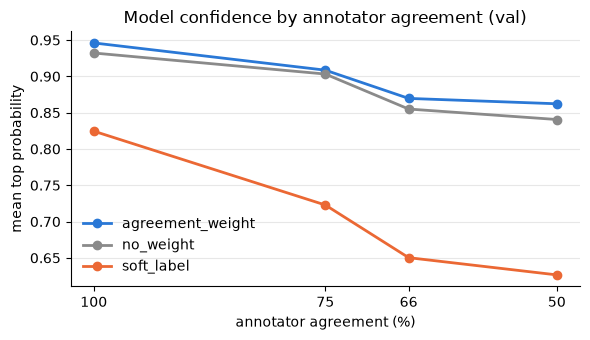

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
colors = {"no_weight": "#8a8a8a", "agreement_weight": "#2a78d6", "soft_label": "#eb6834"}
for arm in confidence.index:
    ax.plot(LEVELS, confidence.loc[arm].values, marker="o", linewidth=2, color=colors.get(arm), label=arm)
ax.set(xlabel="annotator agreement (%)", ylabel="mean top probability",
       title="Model confidence by annotator agreement (val)")
ax.set_xticks(LEVELS)
ax.invert_xaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/agreement_confidence.png", dpi=150)
plt.show()